# 05 — Time series methods: forecast residuals and Matrix Profile

**Goal**: test detectors that model time explicitly, comparing the present with a forecast or with every past subsequence, rather than scoring snapshots of window features.

**Key findings**

- **Forecast residuals detect the onset of a leak, not the leak.** A one-hour-ahead forecast learns that a loaded compressor stays loaded, so the residual is large only while the leak starts. All three variants reach 4/4, but with 2.2–6.4 false alarms per week, and the detection of failure 1 is luck (it falls 12 h after the start, on an isolated dip of the forecast).
- **A contaminated reference blinds the Matrix Profile.** On the raw motor current against the full training period, it detects **0/4**: the nearest training neighbour of every failure subsequence lies in the unreported leak-like episode of March 29 (distances 0.16–0.87, against a median of 2.98 over the test period). For a nearest-neighbour method, a leak seen once in training is normal.
- **Cleaning the reference fixes it.** Removing from the training reference the four leak-like episodes that the expert rule finds in the training period (no test label used) takes the Matrix Profile of the load state from 1/4 to **4/4 with 0.71 false alarms per week**. The z-normalised variant flags failure 4 **11.1 h early**, and its best threshold reaches 4/4 at 0.21 false alarms per week.
- **The same cleaning hurts LOF** (4/4 → 2/4, median over five seeds). The leak-like episode formed a very dense cluster in the training data, and test failures scored high because they sat next to it with a lower density. Without it they blend into the sparse fringe of normal high-load operation: **LOF's result in notebook 04 was partly right for the wrong reason**.
- No time series method beats the best statistical baseline (0.28 false alarms per week). On this dataset, how the reference data is curated matters more than the choice of algorithm.

In [1]:
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
warnings.filterwarnings("ignore", message="X does not have valid feature names")
warnings.filterwarnings("ignore", category=RuntimeWarning, module="stumpy")  # constant subsequences in z-normalised mode

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import stumpy

from metrobench import evaluation as ev
from metrobench import ml
from metrobench import timeseries as ts
from metrobench.data import FAILURES, failure_mask, load, sustained_load_episodes
from metrobench.features import load_features
from metrobench.plotstyle import FAILURE, GAP, INK_MUTED, SERIES, shade_failures, use_style

use_style()
FIG, RESULTS = Path("docs/figures"), Path("results")
grid, X = load_features()
episodes = sustained_load_episodes(load())
unreported = episodes[~episodes.reported]
train_episodes = episodes[episodes.start < ev.SPLIT]  # found by the expert rule on training data only

## 1. Detectors

**Forecast residuals.** A gradient-boosted regressor learns, on the training period, how a window feature evolves from the state observed one hour earlier (all 18 features lagged by 1 h, plus the hour of day). The anomaly score is the positive part of *actual − forecast*: the compressor works more than its recent state predicts. Targets: load share, mean current and mean oil temperature over 30 minutes.

**Matrix Profile.** The minute signal is averaged over 5 minutes and cut into all 2-hour subsequences (24 points). Each subsequence is scored by its distance to the **nearest subsequence of the training period**: a pattern never seen in training gets a large distance (a *discord*). Computed with `stumpy` on two signals (motor current, load state `DV_eletric`) and two distances:

- **raw** (Euclidean on values): a change of level counts;
- **z-normalised**: only the shape of the subsequence counts, not its level.

Each Matrix Profile variant is run against two references:

- the **full** training period;
- a **cleaned** training period, from which the four sustained-load episodes flagged by the expert rule on training data (12, 27, 28 and 28–29 March) are removed. No test label is used.

Settings fixed in advance: 1-hour forecast horizon, 2-hour subsequences.

In [2]:
train_episodes

,start,end,duration,reported
0,2020-03-12 00:43:02,2020-03-12 11:52:48,0 days 11:09:46,False
1,2020-03-27 07:39:06,2020-03-27 11:41:09,0 days 04:02:03,False
2,2020-03-28 07:49:20,2020-03-28 08:49:39,0 days 01:00:19,False
3,2020-03-28 23:05:32,2020-03-29 19:49:14,0 days 20:43:42,False


In [3]:
scores, forecasts = {}, {}
for target, label in [("load_share_30min", "load share"), ("current_mean_30min", "mean current"), ("oil_mean_30min", "mean oil")]:
    scores[f"Forecast residual, {label}"], forecasts[target] = ts.forecast_residual(X, target, ev.SPLIT)
for signal, label in [("Motor_current", "motor current"), ("DV_eletric", "load state")]:
    for normalize, dist in [(False, "raw"), (True, "z-norm")]:
        for exclude, ref in [(None, "full ref."), (train_episodes, "cleaned ref.")]:
            scores[f"Matrix Profile, {label}, {dist}, {ref}"] = ts.matrix_profile(
                grid[signal], ev.SPLIT, normalize=normalize, exclude=exclude)
results = ev.summarize(scores, unreported=unreported)
results.to_csv(RESULTS / "05_time_series.csv")

## 2. Results on the test period

In [4]:
view = results.rename(columns={f"lead_h_{i}": f"lead F{i} (h)" for i in FAILURES.index} | {
    "false_alarms_per_week": "false alarms / week", "false_alarms_in_unreported": "of which unreported episodes",
    "best_detected": "best at budget"})
view[["detected", "lead F1 (h)", "lead F2 (h)", "lead F3 (h)", "lead F4 (h)", "false alarms / week",
      "of which unreported episodes", "best at budget"]].round(2)

,detected,lead F1 (h),lead F2 (h),lead F3 (h),lead F4 (h),false alarms / week,of which unreported episodes,best at budget
detector,,,,,,,,
"Forecast residual, load share",4,-11.83,0.10,0.07,12.27,2.24,4,0.0
"Forecast residual, mean current",4,-11.88,-0.02,0.02,12.27,4.40,11,0.0
"Forecast residual, mean oil",4,-12.37,10.08,0.00,12.53,6.42,4,1.0
"Matrix Profile, motor current, raw, full ref.",0,NaN,NaN,NaN,NaN,0.35,0,0.0
"Matrix Profile, motor current, raw, cleaned ref.",2,NaN,-0.25,-0.83,NaN,0.56,2,0.0
"Matrix Profile, motor current, z-norm, full ref.",3,-18.00,NaN,-6.33,12.67,2.82,2,1.0
"Matrix Profile, motor current, z-norm, cleaned ref.",4,-18.00,-1.58,-1.67,15.00,3.46,10,1.0
"Matrix Profile, load state, raw, full ref.",1,NaN,NaN,NaN,2.58,0.49,0,1.0
"Matrix Profile, load state, raw, cleaned ref.",4,-2.25,-1.25,-1.33,2.58,0.71,3,4.0


Three groups stand out. The forecast residuals detect everything but alarm too often. The Matrix Profile against the full training period is nearly blind (0–3/4). Against the cleaned reference, the Matrix Profile of the load state becomes one of the best detectors of the benchmark: 4/4 with 0.71 false alarms per week, three of its eleven false alarms falling on unreported leak-like episodes. On the motor current, cleaning helps less because the current has more operating variability than the binary load state: z-normalised, it detects 4/4 but with 3.5 false alarms per week.

## 3. Forecast residuals detect changes, not states

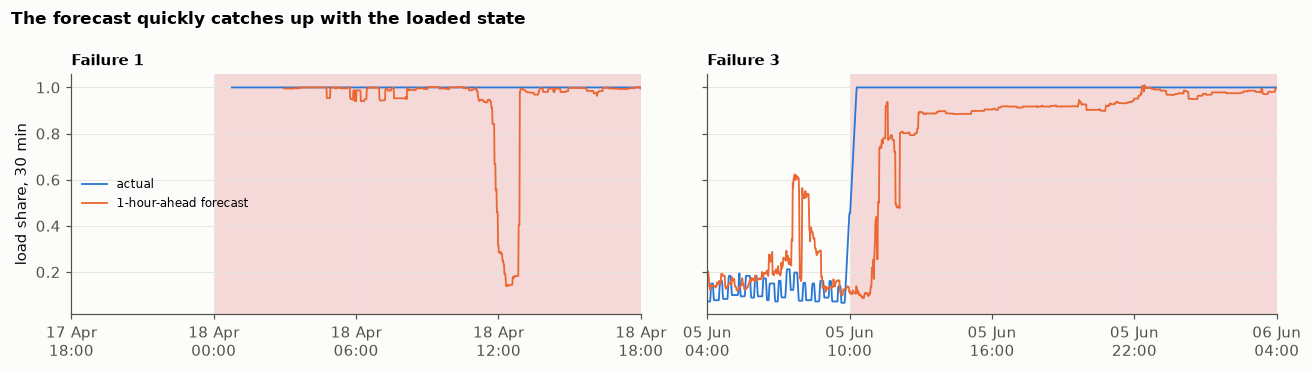

In [5]:
target = "load_share_30min"
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, i in zip(axes, [1, 3]):
    s, e = FAILURES.loc[i, ["start", "end"]]
    w = slice(s - pd.Timedelta("6h"), min(e, s + pd.Timedelta("18h")))
    ax.plot(X.loc[w].index, X.loc[w, target], color=SERIES[0], label="actual")
    ax.plot(forecasts[target].loc[w].index, forecasts[target].loc[w], color=SERIES[1], label="1-hour-ahead forecast")
    shade_failures(ax, FAILURES.loc[[i]], label=False)
    ax.set_xlim(w.start, w.stop)
    ax.set_title(f"Failure {i}", fontsize=10)
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
axes[0].set_ylabel("load share, 30 min")
axes[0].legend(loc="center left", fontsize=8)
fig.suptitle("The forecast quickly catches up with the loaded state", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "05_forecast.png")
plt.show()

A forecast from the recent past predicts that a compressor loaded an hour ago is still loaded. The residual is large only while the leak *starts*, then falls back to zero. A detector of changes is a poor detector of a lasting state, and it raises an alarm at every unusually long loaded period, hence 2–6 false alarms per week.

Failure 1 is a further trap: it begins right after a frozen stretch, so no forecast exists during its first 1.5 hours (the lagged features are missing). The forecast then predicts "loaded" and the residual stays at zero; the "detection" 12 hours after the start comes from an isolated dip of the forecast. It counts in the table, but it is luck.

In [6]:
horizons = {}
for h in ["30min", "1h", "3h", "6h"]:
    horizons[f"forecast residual, load share, horizon {h}"] = ts.forecast_residual(X, "load_share_30min", ev.SPLIT, horizon=h)[0]
ev.summarize(horizons)[["detected", "lead_h_1", "lead_h_4", "false_alarms_per_week"]].round(2)

,detected,lead_h_1,lead_h_4,false_alarms_per_week
detector,,,,
"forecast residual, load share, horizon 30min",4,-11.67,10.17,2.83
"forecast residual, load share, horizon 1h",4,-11.83,12.27,2.24
"forecast residual, load share, horizon 3h",3,NaN,12.43,1.78
"forecast residual, load share, horizon 6h",4,-11.88,9.32,1.58


Sensitivity to the horizon, for transparency only (computed on the test period, not used for selection): longer horizons reduce false alarms (from 2.8 per week at 30 minutes to 1.6 at 6 hours) because the forecast leans less on the immediate state, but none reaches one false alarm per week, and failure 1 is only ever caught by chance, ~12 h after its start.

## 4. Matrix Profile: the nearest neighbour of a leak is a leak

In [7]:
coarse = grid.Motor_current.resample("5min").mean()
train5, test5 = coarse[coarse.index < ev.SPLIT], coarse[coarse.index >= ev.SPLIT]
m = 24
mp = np.asarray(stumpy.stump(test5.to_numpy(float), m, T_B=train5.to_numpy(float), ignore_trivial=False, normalize=False))
distance = pd.Series(np.asarray(mp[:, 0], dtype=float), index=test5.index[m - 1:]).replace(np.inf, np.nan)
neighbour = pd.Series(np.asarray(mp[:, 1], dtype=np.int64), index=test5.index[m - 1:])
rows = []
for i, (s, e) in FAILURES[["start", "end"]].iterrows():
    d = distance.loc[s + pd.Timedelta("2h"): e].dropna()
    t = d.index[len(d) // 2]
    rows.append({"failure": i, "median distance during failure": d.median(),
                 "nearest training subsequence starts": train5.index[neighbour[t]]})
print(f"median distance over the whole test period: {distance.median():.2f}")
pd.DataFrame(rows).set_index("failure").round({"median distance during failure": 2})

median distance over the whole test period: 2.98


,median distance during failure,nearest training subsequence starts
failure,,
1,0.17,2020-03-29 09:10:00
2,0.16,2020-03-29 10:45:00
3,0.31,2020-03-29 14:00:00
4,0.87,2020-03-29 11:25:00


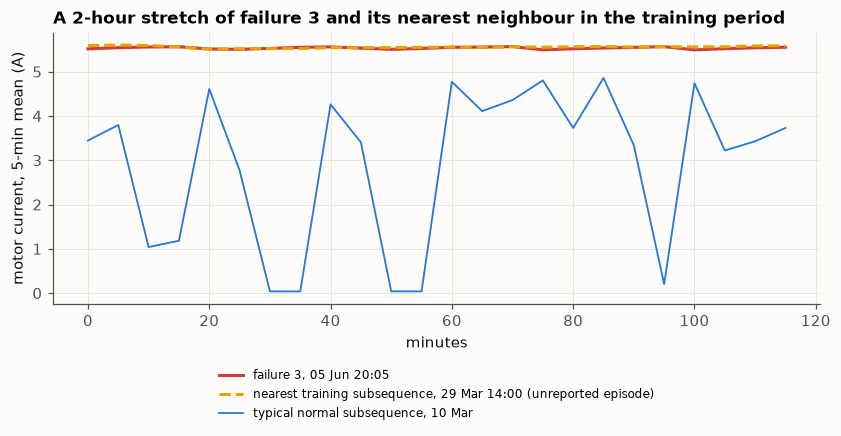

In [8]:
i = 3
s = FAILURES.loc[i, "start"] + pd.Timedelta("12h")
t = distance.loc[s:].index[0]
seq = test5.loc[:t].iloc[-m:]
nn_start = neighbour[t]
nn = train5.iloc[nn_start: nn_start + m]
normal = train5.loc["2020-03-10 10:00":].iloc[:m]
fig, ax = plt.subplots(figsize=(9, 3.2))
minutes = np.arange(m) * 5
ax.plot(minutes, seq.to_numpy(), color=FAILURE, lw=2, label=f"failure {i}, {seq.index[0]:%d %b %H:%M}")
ax.plot(minutes, nn.to_numpy(), color=SERIES[3], lw=2, ls="--", label=f"nearest training subsequence, {nn.index[0]:%d %b %H:%M} (unreported episode)")
ax.plot(minutes, normal.to_numpy(), color=SERIES[0], lw=1.2, label="typical normal subsequence, 10 Mar")
ax.set_xlabel("minutes")
ax.set_ylabel("motor current, 5-min mean (A)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1, fontsize=8)
ax.set_title("A 2-hour stretch of failure 3 and its nearest neighbour in the training period")
fig.savefig(FIG / "05_matrix_profile_neighbour.png")
plt.show()

During failure 3 the motor current is flat at ~5.5 A: the compressor never stops. The normal subsequence oscillates between 0 and 5 A with the 20-minute cycle. The nearest training neighbour of the failure subsequence is the March 29 episode, indistinguishable from it. This is the label-noise issue of notebook 01 in its most direct form: a nearest-neighbour detector can only flag what has never happened, and the leak had already happened, unreported, in the training period.

## 5. Does cleaning the reference help other detectors?

The cleaning only uses the expert rule on training data, so it can be applied to any detector that learns from the training period. Cross-check on LOF, the best detector of notebook 04 (five seeds):

In [9]:
X_train, _ = ev.split(X)
clean_train = X_train[~failure_mask(X_train.index, train_episodes)]
lof_runs = []
for seed in range(5):
    for name, T in [("LOF, full training data", X_train), ("LOF, cleaned training data", clean_train)]:
        r = ev.summarize({name: ml.local_outlier_factor(X, T, seed=seed)}, unreported=unreported)
        lof_runs.append(r.assign(seed=seed))
lof_runs = pd.concat(lof_runs)
lof_runs.groupby(level=0)[["detected", "lead_h_4", "false_alarms_per_week"]].agg(["median", "min", "max"]).round(2)

detected         lead_h_4                \
                             median min max   median    min    max   
detector                                                             
LOF, cleaned training data      2.0   1   2    12.83  12.73  12.88   
LOF, full training data         4.0   4   4    12.60   9.90  12.82   

                           false_alarms_per_week              
                                          median   min   max  
detector                                                      
LOF, cleaned training data                  1.10  0.90  1.17  
LOF, full training data                     0.55  0.35  1.17

Cleaning the reference is not a universal fix. For the Matrix Profile, the leak-like training episodes were near-duplicates of the failures and hid them. For LOF, they created a dense cluster next to which failures looked sparse, so they *helped*. Once removed, failure points are as isolated as the normal high-load points at the edge of the training data, and LOF scores them around 1.7, like ordinary operation. A result that depends on an accident of the training data would not survive a new training period, which is why the final comparison reports LOF with this caveat.

## 6. Verdict

| | Best time series result | Best earlier result |
|---|---|---|
| Failures detected | 4/4 (Matrix Profile, load state, cleaned reference) | 4/4 (several) |
| False alarms per week | 0.71 | 0.28 (rolling-baseline oil z, notebook 03) |
| Early warning on failure 4 | 11.1 h (z-normalised variant) | 12.9 h (CUSUM, motor current) |
| Requires | a curated reference | one feature |

Modelling time explicitly does not pay off here: the leak signature is a sustained state, which window features already summarise. The lasting lesson of this notebook is about data: every method that learns "normal" from the training period inherits its unreported leaks, sometimes as blindness (Matrix Profile), sometimes as a lucky crutch (LOF). The last family, deep autoencoders, is tested in notebook 06 with both the full and the cleaned training data.